In [3]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances, signals

In [4]:
# def points_to_voxel_index(p, L):
#     """
#     converts points (x,y,z) in [-1,1]^3 to voxel indices in [0, L-1]^3
#     input: p is 3 X n_points array
#     """

#     p_norm = (p + 1) / 2 * (L-1)
#     v_idx = np.floor(p_norm.T).astype('int')

#     return v_idx


# def fill_voxel_array(v_idx, L, value=1):
#     """fill voxel array at specified index with value"""

#     ### figure out best conventions, currently:
#     ### * UPDATE THIS
#     ### - Cartesian x --> Numpy z (axis=0)
#     ### - Cartesian y --> Numpy y (axis=1)
#     ### - Cartesian z --> Numpy x (axis=2)

#     f = np.zeros((L,L,L))

#     vx = v_idx[:, 0]
#     vy = v_idx[:, 1]
#     vz = v_idx[:, 2]

#     f[vx, -vz, vy] = value
    
#     return f


# def generate_voxel_array_from_points(p, L, value=1):
    
#     v_idx = points_to_voxel_index(p, L)
#     f = fill_voxel_array(v_idx, L, value)

#     return f

In [5]:
# # p = np.array([[0, -0.33, 0.33], [0, 0, -0.33], [0, 0.33, 0.33]]).T
# # # p = np.array([[0, -0.33, 0.33], [0, 0, -0.33], [0, 0.33, 0.33], [-0.4, 0.4, -0.4]]).T
# # # p = np.array([0, 0, 0.5]).reshape(3,1)

# p = np.array([[0, 0.33, 0.25], [0.1, -0.33, 0]]).T

# ### what conventions / axes / order to use here?
# omega = np.deg2rad(0)
# theta = np.deg2rad(180)
# phi = np.deg2rad(90)

# R1 = transforms.rotate_z(omega)
# R2 = transforms.rotate_y(theta)
# R3 = transforms.rotate_z(phi)
# R = R1 @ R3 @ R2

# ### check the rotation order
# q = R @ p

# L = 49
# sigma = 2

# f = generate_voxel_array_from_points(p, L)
# g = generate_voxel_array_from_points(q, L)
# z = utils.generate_centered_gaussian(L=L, d=3, sigma=sigma)

# F = utils.signal_convolution(f, z)
# G = utils.signal_convolution(g, z)

# F = signals.Signal(F, d=3).preprocess_signals()
# G = signals.Signal(G, d=3).preprocess_signals()

# print('\t original')
# plots.orthogonal_2D_projection_plot(F[0])
# print('\t rotated')
# plots.orthogonal_2D_projection_plot(G[0])

	 original


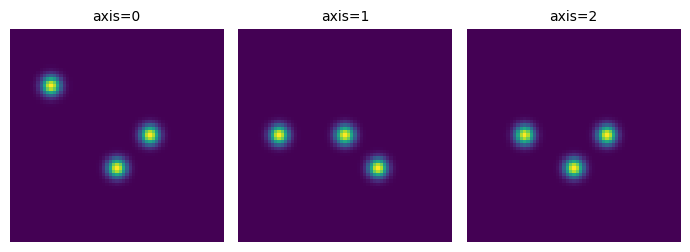

	 rotated


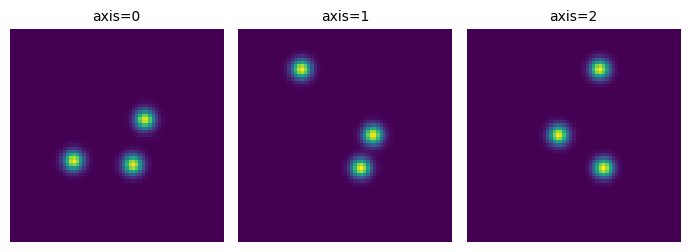

In [6]:
L = 65
sigma = 2

f = utils.generate_centered_gaussian(L=L, d=3, sigma=sigma)
f_1 = transforms.translate_3d(f, 0, 10, 0)
f_2 = transforms.translate_3d(f, 0, -15, -20)
f_3 = transforms.translate_3d(f, 10, 0, 10)
F = f_1 + f_2 + f_3

F = signals.Signal(F, d=3).preprocess_signals()[0]

z_rt = transforms.Transform(F, d=3).radon_transform()[0]
z_cdf = transforms.Transform(F, d=3).cdf_transform()[0]
z_icdf = transforms.Transform(F, d=3).inverse_cdf_transform()[0]

thetas = np.linspace(0, np.pi, L, endpoint=True)
phis = np.linspace(0, 2*np.pi, L, endpoint=False)

omega = np.deg2rad(0)
theta = np.deg2rad(120)
phi = np.deg2rad(90)

G = transforms.rotate_voxel_zyz(F, omega, theta, phi, order=1)
G = signals.Signal(G, d=3).preprocess_signals()[0]

print('\t original')
plots.orthogonal_2D_projection_plot(F)
print('\t rotated')
plots.orthogonal_2D_projection_plot(G)

In [7]:
# L = 69
# sigma = 3

# omega = -np.deg2rad(0)
# theta = -np.deg2rad(35)
# phi = -np.deg2rad(115)

# F = utils.generate_3d_triangle_gaussian_shape(L, sigma)
# G = transforms.rotate_voxel_zyz(F, omega, theta, phi, order=1)

# F = signals.Signal(F, d=3).preprocess_signals()
# G = signals.Signal(G, d=3).preprocess_signals()

# print('\t original')
# plots.orthogonal_2D_projection_plot(F[0])
# print('\t rotated')
# plots.orthogonal_2D_projection_plot(G[0])

In [8]:
# L = 49
# sigma = 2

# tz1, ty1, tx1 = -5, 0, -5
# a = utils.generate_centered_gaussian(L=L, d=3, sigma=sigma)
# a = transforms.translate_3d(a, tz1, ty1, tx1)

# tz2, ty2, tx2 = 0, 10, 10
# b = utils.generate_centered_gaussian(L=L, d=3, sigma=sigma)
# b = transforms.translate_3d(b, tz2, ty2, tx2)

# omega = -np.deg2rad(0)
# theta = -np.deg2rad(45)
# phi = -np.deg2rad(0)

# F = a + b
# G = rotate_voxel_zyz(F, omega, theta, phi, order=1)

# F = signals.Signal(F, d=3).preprocess_signals()
# G = signals.Signal(G, d=3).preprocess_signals()

# print('\t original')
# plots.orthogonal_2D_projection_plot(F[0])
# print('\t rotated')
# plots.orthogonal_2D_projection_plot(G[0])

In [9]:
U = transforms.Transform(F, d=3, apply_ramp=False).inverse_cdf_transform()[0]
V = transforms.Transform(G, d=3, apply_ramp=False).inverse_cdf_transform()[0]

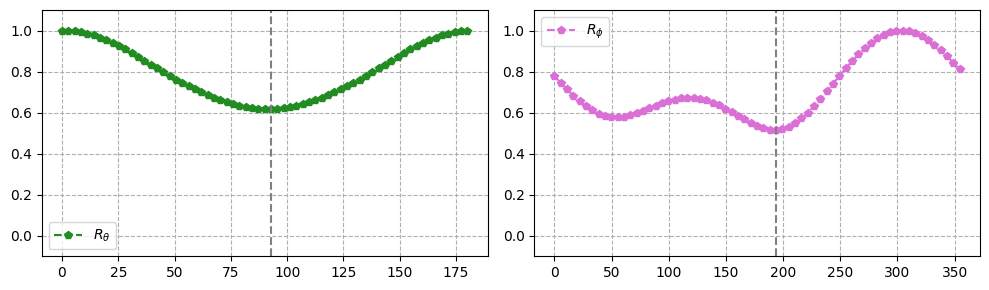

			 min_theta:  92.812 					 min_phi:  193.846
			  gt_theta:  120.0 					  gt_phi:  90.0


In [10]:
### Test rotations in either theta or phi individually by shifting tensor
n_phi, n_points, n_theta = U.shape

dists_sw_theta = np.zeros(n_theta)
dists_sw_phi = np.zeros(n_phi)

for theta_idx in range(n_theta):
    V_theta = transforms.translate_3d(V, 0, 0, theta_idx)
    # dists_sw_theta[theta_idx] = np.mean((U - V_theta)**2)
    dists_sw_theta[theta_idx] = np.mean( np.mean( (U - V_theta)**2 , axis=1 ) * np.sin(thetas) )
    
for phi_idx in range(n_phi):
    V_phi = transforms.translate_3d(V, phi_idx, 0, 0)
    # dists_sw_phi[phi_idx] = np.mean((U - V_phi)**2)
    dists_sw_phi[phi_idx] = np.mean( np.mean( (U - V_phi)**2 , axis=1 ) * np.sin(thetas) )

dists_sw_theta = dists_sw_theta / np.amax(dists_sw_theta)
dists_sw_phi = dists_sw_phi / np.amax(dists_sw_phi)


min_theta = thetas[np.argmin(dists_sw_theta)]
min_phi = phis[np.argmin(dists_sw_phi)]

fig, axs = plt.subplots(1, 2, figsize=(10, 3))

axs[0].plot(np.rad2deg(thetas), dists_sw_theta, 'p--', color='forestgreen', label=r'$R_\theta$')
axs[0].grid(which='major', linestyle='--')
axs[0].axvline(np.rad2deg(min_theta), linestyle='--', color='gray')
axs[0].set_ylim(-0.1, 1.1)
axs[0].legend()

axs[1].plot(np.rad2deg(phis), dists_sw_phi, 'p--', color='orchid', label=r'$R_\phi$')
axs[1].grid(which='major', linestyle='--')
axs[1].axvline(np.rad2deg(min_phi), linestyle='--', color='gray')
axs[1].set_ylim(-0.1, 1.1)
axs[1].legend()

plt.tight_layout()
plt.show()

print('\t\t\t min_theta: ', np.round(np.rad2deg(min_theta), 3), '\t\t\t\t\t min_phi: ', np.round(np.rad2deg(min_phi), 3))
print('\t\t\t  gt_theta: ', np.round(np.rad2deg(theta), 3), '\t\t\t\t\t  gt_phi: ', np.round(np.rad2deg(phi), 3))

In [9]:
### Loop through rotations of phi for each rotation of theta

n_phi, n_points, n_theta = U.shape
thetas = np.linspace(0, np.pi, n_theta, endpoint=True)
phis = np.linspace(0, 2*np.pi, n_phi, endpoint=False)

dists_sw_theta_phi = np.zeros((n_theta, n_phi))

t = time.time()

for theta_idx in range(n_theta):
    for phi_idx in range(n_phi):
        V_theta_phi = transforms.translate_3d(V, phi_idx, 0, theta_idx)
        # dists_sw_theta_phi[theta_idx, phi_idx] = np.mean((U - V_theta_phi)**2)
        dists_sw_theta_phi[theta_idx, phi_idx] = np.mean( np.mean( (U - V_theta_phi)**2 , axis=1 ) * np.sin(thetas) )

print('rotation distance time: ', time.time() - t)

rotation distance time:  3.699972152709961


In [10]:
dists_sw_theta_phi = dists_sw_theta_phi / np.amax(dists_sw_theta_phi)

min_theta, min_phi = distances.return_min_angles(dists_sw_theta_phi, thetas, phis)

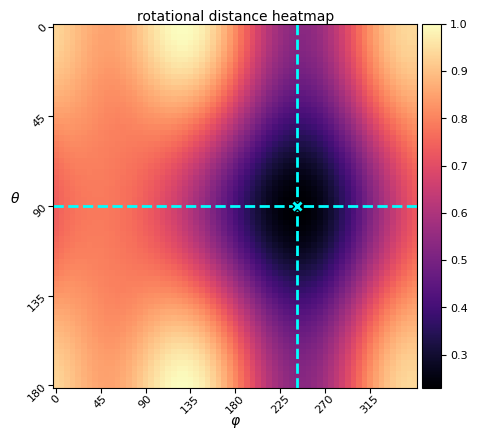



min_theta =  90.0
  min_phi =  238.15


In [11]:
plots.rotational_distance_heatmap(dists_sw_theta_phi, ticks='degrees')
print('\n')
print('min_theta = ', np.round(np.rad2deg(min_theta), 2))
print('  min_phi = ', np.round(np.rad2deg(min_phi), 2))

In [12]:
### Next try fast rotations with 2D DFT
### should I add the conjugation? transpose at end?
### do I need extra conjugation / flip because sum axis=1 flips axis in summed array

n_phi, n_points, n_theta = U.shape
thetas = np.linspace(0, np.pi, n_theta, endpoint=True)
phis = np.linspace(0, 2*np.pi, n_phi, endpoint=False)

C = np.zeros(U.shape)

t = time.time()

U_norm = np.linalg.norm(U)**2
V_norm = np.linalg.norm(V)**2

for s in range(n_points):
    
    U_slice = U[:, s, :]
    V_slice = V[:, s, :]

    ### where should conjugation / normalization / vol element be ?
    # C[:, s, :] =  np.fft.ifft2(np.fft.fft2(U_slice) * np.conj(np.fft.fft2(V_slice))).real
    C[:, s, :] =  np.fft.ifft2(np.fft.fft2(U_slice) * np.conj(np.fft.fft2(V_slice))).real

# C = C * np.sin(thetas)[np.newaxis, np.newaxis, :]

dists_sw_theta_phi = U_norm + V_norm - 2*np.sum(C, axis=1)

print('rotation distance time: ', time.time() - t)

rotation distance time:  0.024951457977294922


In [13]:
dists_sw_theta_phi = dists_sw_theta_phi / np.amax(dists_sw_theta_phi)

dists_sw_theta_phi = dists_sw_theta_phi.T  

min_theta, min_phi = distances.return_min_angles(dists_sw_theta_phi, thetas, phis)

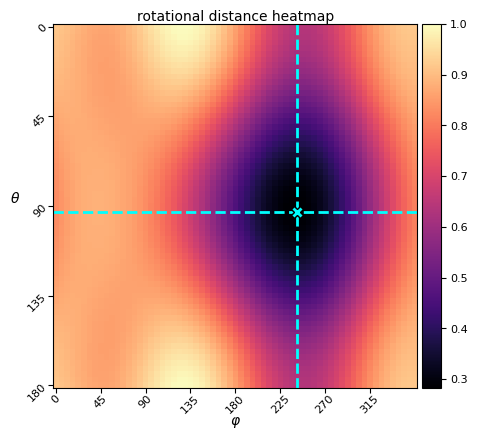



min_theta =  92.81
  min_phi =  238.15


In [14]:
plots.rotational_distance_heatmap(dists_sw_theta_phi)
print('\n')
print('min_theta = ', np.round(np.rad2deg(min_theta), 2))
print('  min_phi = ', np.round(np.rad2deg(min_phi), 2))

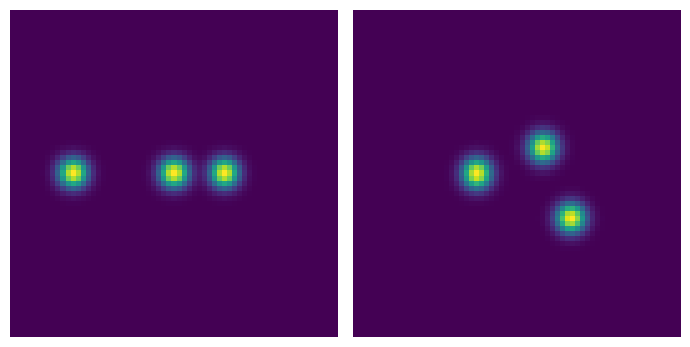

In [15]:
### Then compute the rotation for omega
### need to rotate G by theta, phi first, right?
### then align by in-plane rotation of the projection

# G_theta_phi = rotate_voxel_zyz(G[0], 0, 0, 0, order=1)
# G_theta_phi = transforms.rotate_voxel_zyz(G[0], -phi, -theta, 0, order=1)  # ground truth check
G_theta_phi = transforms.rotate_voxel_zyz(G, -min_phi, -min_theta, 0, order=1)  # flip order and sign to undo rotation?

### confirm which axis to use for z-axis projection
F2d = np.sum(F, axis=1)
G2d = np.sum(G_theta_phi, axis=1)

plots.two_imshow(F2d, G2d)

In [16]:
omega = np.linspace(0, 2*np.pi, L, endpoint=False)

t = time.time()
U2d = transforms.Transform(F2d, d=2, apply_ramp=False).inverse_cdf_transform()[0]
V2d = transforms.Transform(G2d, d=2, apply_ramp=False).inverse_cdf_transform()[0]

d_sw_omega = distances.fast_rotational_distance_2d(U2d, V2d)
print('rotational distance time :', time.time() - t)

d_sw_omega = d_sw_omega / np.amax(d_sw_omega)
min_omega = omega[np.argmin(d_sw_omega)]

d_l2_omega = distances.rotational_euclidean_distance_2d(F2d, G2d, np.rad2deg(omega))
d_l2_omega = d_l2_omega / np.amax(d_l2_omega)
min_omega_l2 = omega[np.argmin(d_l2_omega)]

rotational distance time : 0.004584789276123047


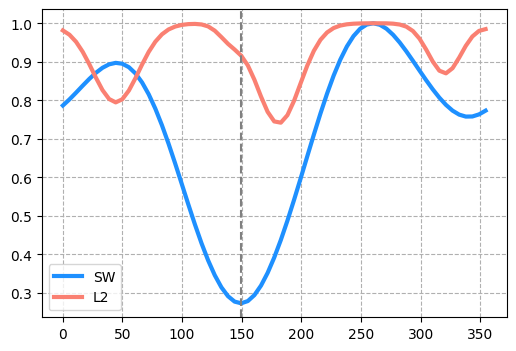

min_omega =  149.53846153846152


In [17]:
### add this to plots

plt.figure(figsize=(6,4))
plt.plot(np.rad2deg(omega), d_sw_omega, linewidth=3, color='dodgerblue', label='SW')
plt.plot(np.rad2deg(omega), d_l2_omega, linewidth=3, color='salmon', label='L2')
plt.axvline(np.rad2deg(min_omega), linewidth=1.5, linestyle='--', color='grey')
plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

print('min_omega = ', np.rad2deg(min_omega))
# print('min_omega = ', np.rad2deg(min_omega_l2))

In [18]:
print(np.rad2deg(omega))

[  0.           5.53846154  11.07692308  16.61538462  22.15384615
  27.69230769  33.23076923  38.76923077  44.30769231  49.84615385
  55.38461538  60.92307692  66.46153846  72.          77.53846154
  83.07692308  88.61538462  94.15384615  99.69230769 105.23076923
 110.76923077 116.30769231 121.84615385 127.38461538 132.92307692
 138.46153846 144.         149.53846154 155.07692308 160.61538462
 166.15384615 171.69230769 177.23076923 182.76923077 188.30769231
 193.84615385 199.38461538 204.92307692 210.46153846 216.
 221.53846154 227.07692308 232.61538462 238.15384615 243.69230769
 249.23076923 254.76923077 260.30769231 265.84615385 271.38461538
 276.92307692 282.46153846 288.         293.53846154 299.07692308
 304.61538462 310.15384615 315.69230769 321.23076923 326.76923077
 332.30769231 337.84615385 343.38461538 348.92307692 354.46153846]


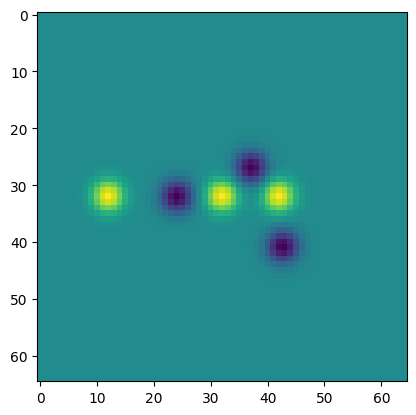

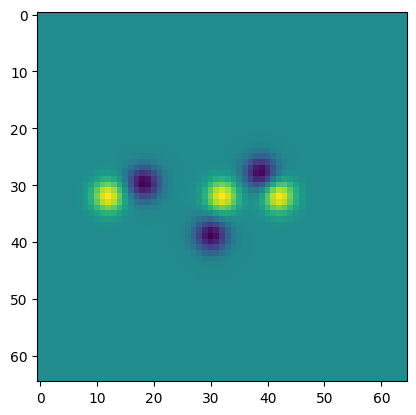

In [21]:
G2d_aligned = utils.rotate_image(G2d, -np.rad2deg(min_omega))
# G2d_aligned = utils.rotate_image(G2d, -180)

plt.imshow(F2d - G2d)
plt.show()
plt.imshow(F2d - G2d_aligned)
plt.show()